# CIFAR-10 Image Classifier

Build and evaluate a convolutional neural network on CIFAR-10. The submission target is at least **45% test accuracy**; the hypothetical Detectocorp benchmark is **70%**. Actual accuracy is measured below, not assumed.

Run all cells in order in a workspace with `torch`, `torchvision`, `numpy`, and `matplotlib` installed. The first data-loading run downloads CIFAR-10 into `./data` and needs internet access. Training defaults to 20 epochs and automatically selects CUDA, Apple MPS, or CPU; CPU training may take considerably longer. Outputs and trained weights will be created when you execute this notebook.

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 1e-3
DATA_DIR = Path('data')
OUTPUT_DIR = Path('artifacts')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'PyTorch {torch.__version__}; device: {device}')
print('Seeds improve repeatability; exact results can differ across devices.')

PyTorch 2.0.1; device: cuda
Seeds improve repeatability; exact results can differ across devices.


## Data loading and augmentation

CIFAR-10 contains 50,000 training images and 10,000 test images in 10 balanced classes. Each image is 32 x 32 with three RGB channels. `ToTensor()` converts images to floating-point tensors in channel-first format, and normalization scales each channel using fixed CIFAR-10 training-set statistics.

Random cropping with padding and horizontal flipping augment **training only**, helping the model tolerate small translations and changes in orientation. A seeded split reserves 5,000 training images for validation; validation and test transforms are deterministic. Model selection uses validation accuracy, keeping the test set out of training and hyperparameter decisions.

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

full_train_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform
)
validation_source = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=False, transform=test_transform
)
test_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=test_transform
)
split_generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train_dataset), generator=split_generator).tolist()
validation_indices = indices[:5000]
training_indices = indices[5000:]
train_dataset = Subset(full_train_dataset, training_indices)
validation_dataset = Subset(validation_source, validation_indices)
classes = full_train_dataset.classes

# Zero workers also supports notebook kernels without multiprocessing setup.
loader_options = dict(batch_size=BATCH_SIZE, num_workers=0,
                      pin_memory=device.type == 'cuda')
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options
)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

100%|██████████| 170498071/170498071 [28:23<00:00, 100087.60it/s]


Extracting data/cifar-10-python.tar.gz to data
Files already downloaded and verified


Raw training data shape: (50000, 32, 32, 3) (N, H, W, C)
Training: 45,000; validation: 5,000; test: 10,000
Transformed training image: shape=(3, 32, 32), dtype=torch.float32; label=deer
Training batch shape: (128, 3, 32, 32)
Full training class counts: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


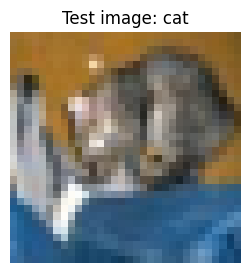

In [3]:
print(f'Raw training data shape: {full_train_dataset.data.shape} (N, H, W, C)')
print(f'Training: {len(train_dataset):,}; validation: {len(validation_dataset):,}; '
      f'test: {len(test_dataset):,}')
example_image, example_label = train_dataset[0]
print(f'Transformed training image: shape={tuple(example_image.shape)}, '
      f'dtype={example_image.dtype}; label={classes[example_label]}')
print(f'Training batch shape: {(min(BATCH_SIZE, len(train_dataset)), *example_image.shape)}')
counts = np.bincount(full_train_dataset.targets, minlength=len(classes))
print('Full training class counts:', dict(zip(classes, counts.tolist())))

test_image, test_label = test_dataset[0]
display_image = test_image * torch.tensor(STD)[:, None, None]
display_image = display_image + torch.tensor(MEAN)[:, None, None]
plt.figure(figsize=(3, 3))
plt.imshow(display_image.permute(1, 2, 0).clamp(0, 1).numpy())
plt.title(f'Test image: {classes[test_label]}')
plt.axis('off')
plt.show()

## Model design

Three convolutional blocks learn local features with 32, 64, and 128 channels. Each block uses two padded 3 x 3 convolutions, batch normalization, ReLU, and pooling, reducing 32 x 32 inputs to 4 x 4 feature maps. A 256-unit classifier with dropout produces 10 outputs, one per class; this is sized for small RGB images rather than a large-image network.

`Model.forward()` returns softmax probabilities, with each row summing to one. Training uses the same network's `forward_logits()` with `CrossEntropyLoss`, which internally applies log-softmax for numerical stability; feeding softmax probabilities to cross-entropy would be incorrect. AdamW updates parameters, weight decay and dropout regularize learning, and a cosine schedule lowers the learning rate over training.

In [4]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()

        def block(in_channels, out_channels):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 10),
        )

    def forward_logits(self, images):
        return self.classifier(self.features(images))

    def forward(self, images):
        return torch.softmax(self.forward_logits(images), dim=1)


model = Model().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
print(model)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

model.eval()
with torch.inference_mode():
    probabilities = model(example_image.unsqueeze(0).to(device))
assert probabilities.shape == (1, 10)
assert torch.isfinite(probabilities).all().item()
assert (probabilities >= 0).all().item()
assert torch.allclose(probabilities.sum(dim=1), torch.ones(1, device=device), atol=1e-5)
print('Verified: forward returns 10 probabilities summing to one.')

Model(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=

## Training and validation

Every training batch performs a forward pass, classification loss calculation, backpropagation, and optimizer update. Epoch losses are sample-weighted averages, including the smaller last batch. Validation runs without gradients or augmentation, and the best validation checkpoint is kept on CPU independently of later parameter updates. Use validation curves, not repeated test measurements, if adjusting epochs, learning rate, or regularization.

In [5]:
history = {'train_loss': [], 'validation_loss': [],
           'train_accuracy': [], 'validation_accuracy': []}
best_validation_accuracy = -1.0
best_state = None
best_epoch = None

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model.forward_logits(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss).item():
            raise RuntimeError(f'Non-finite training loss in epoch {epoch + 1}')
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    history['train_loss'].append(total_loss / total)
    history['train_accuracy'].append(correct / total)

    model.eval()
    validation_loss = 0.0
    validation_correct = 0
    validation_total = 0
    with torch.inference_mode():
        for images, labels in validation_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model.forward_logits(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss).item():
                raise RuntimeError(f'Non-finite validation loss in epoch {epoch + 1}')
            validation_loss += loss.item() * labels.size(0)
            validation_correct += (logits.argmax(dim=1) == labels).sum().item()
            validation_total += labels.size(0)

    history['validation_loss'].append(validation_loss / validation_total)
    validation_accuracy = validation_correct / validation_total
    history['validation_accuracy'].append(validation_accuracy)
    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        best_epoch = epoch + 1
        best_state = copy.deepcopy({key: value.cpu() for key, value in model.state_dict().items()})
        torch.save(best_state, OUTPUT_DIR / 'cifar10_best_weights.pth')
    scheduler.step()
    print(f'Epoch {epoch + 1:02d}/{EPOCHS}: '
          f'train loss={history["train_loss"][-1]:.4f}, '
          f'validation loss={history["validation_loss"][-1]:.4f}, '
          f'train accuracy={history["train_accuracy"][-1]:.2%}, '
          f'validation accuracy={validation_accuracy:.2%}')

if best_state is None:
    raise RuntimeError('No trained checkpoint exists; EPOCHS must be positive.')
model.load_state_dict(best_state)
model.eval()
print(f'Restored epoch {best_epoch}, validation accuracy={best_validation_accuracy:.2%}')

Epoch 01/20: train loss=1.5542, validation loss=1.1661, train accuracy=42.45%, validation accuracy=56.66%
Epoch 02/20: train loss=1.1567, validation loss=1.0215, train accuracy=58.69%, validation accuracy=63.90%
Epoch 03/20: train loss=0.9851, validation loss=0.9603, train accuracy=64.99%, validation accuracy=66.84%
Epoch 04/20: train loss=0.8865, validation loss=0.7451, train accuracy=69.15%, validation accuracy=73.08%
Epoch 05/20: train loss=0.8008, validation loss=0.7576, train accuracy=72.32%, validation accuracy=74.44%
Epoch 06/20: train loss=0.7260, validation loss=0.6477, train accuracy=75.02%, validation accuracy=77.84%
Epoch 07/20: train loss=0.6782, validation loss=0.6555, train accuracy=76.98%, validation accuracy=77.44%
Epoch 08/20: train loss=0.6291, validation loss=0.6027, train accuracy=78.55%, validation accuracy=79.22%
Epoch 09/20: train loss=0.5856, validation loss=0.5623, train accuracy=80.17%, validation accuracy=80.96%
Epoch 10/20: train loss=0.5507, validation los

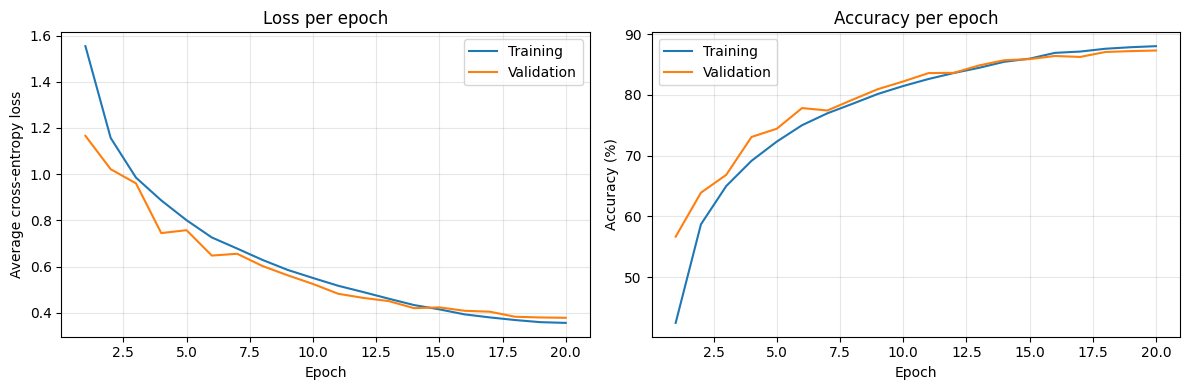

In [6]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history['train_loss'], label='Training')
axes[0].plot(epochs, history['validation_loss'], label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Average cross-entropy loss', title='Loss per epoch')
axes[1].plot(epochs, np.array(history['train_accuracy']) * 100, label='Training')
axes[1].plot(epochs, np.array(history['validation_accuracy']) * 100, label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Accuracy per epoch')
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Test evaluation

The held-out test loader measures top-1 accuracy for the selected model. Evaluation disables dropout and gradient recording. The confusion matrix has true labels on rows and predictions on columns. The final check explicitly reports whether the measured accuracy meets 45%; running this notebook is necessary to establish that result.

Test accuracy: 86.40% (8,640/10,000)
45% requirement: PASS
  airplane: 91.00%
automobile: 94.80%
      bird: 81.10%
       cat: 69.70%
      deer: 86.80%
       dog: 78.10%
      frog: 90.90%
     horse: 87.90%
      ship: 92.50%
     truck: 91.20%


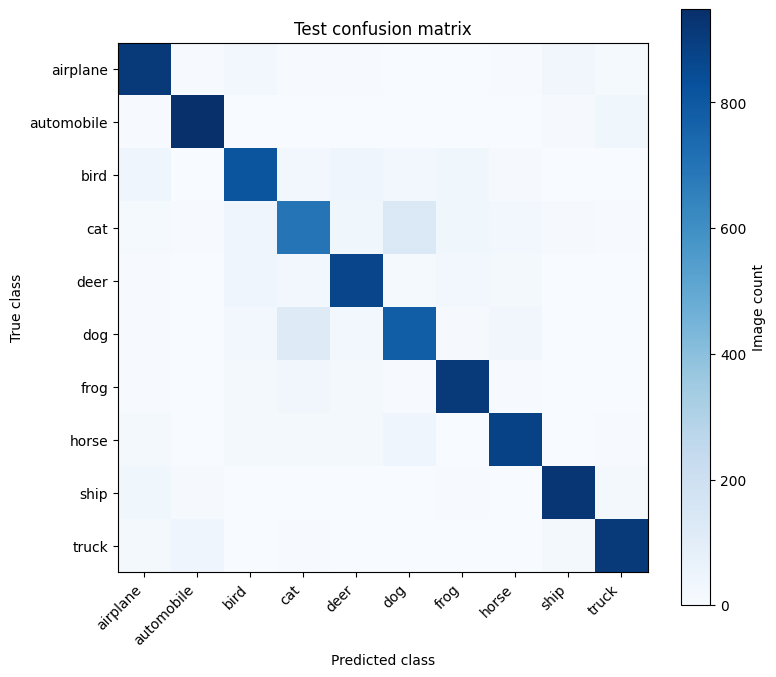

In [7]:
model.eval()
test_correct = 0
test_total = 0
confusion = torch.zeros(10, 10, dtype=torch.long)
with torch.inference_mode():
    for images, labels in test_loader:
        probabilities = model(images.to(device))
        if not torch.isfinite(probabilities).all().item():
            raise RuntimeError('Test predictions contain non-finite probabilities.')
        predictions = probabilities.argmax(dim=1).cpu()
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)
        confusion += torch.bincount(10 * labels + predictions, minlength=100).reshape(10, 10)

assert test_total == len(test_dataset), 'Evaluation must include every test sample.'
test_accuracy = test_correct / test_total
meets_target = test_accuracy >= 0.45
print(f'Test accuracy: {test_accuracy:.2%} ({test_correct:,}/{test_total:,})')
print(f'45% requirement: {"PASS" if meets_target else "FAIL"}')
if not meets_target:
    print('The measured result does not meet the requirement. Revisit training and '
          'validation performance; this run must not be submitted as passing.')

for index, name in enumerate(classes):
    class_accuracy = confusion[index, index].item() / confusion[index].sum().item()
    print(f'{name:>10}: {class_accuracy:.2%}')

fig, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(confusion.numpy(), cmap='Blues')
axis.set(xticks=range(10), yticks=range(10), xticklabels=classes, yticklabels=classes,
         xlabel='Predicted class', ylabel='True class', title='Test confusion matrix')
plt.setp(axis.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(image, ax=axis, label='Image count')
plt.tight_layout()
plt.show()

## Results and build-versus-buy recommendation

The next cell writes a recommendation of at least three sentences using the **actual measured test accuracy** and the hypothetical 70% Detectocorp benchmark. It does not invent a result before training. CIFAR-10 classification is not object detection: a real procurement decision also needs representative detection data, localization metrics such as mAP, latency, cost, and maintenance analysis.

In [8]:
benchmark = 0.70
difference = 100 * (test_accuracy - benchmark)
sentences = [
    f'My CNN achieved {test_accuracy:.2%} test accuracy on {test_total:,} CIFAR-10 images, '
    f'and it {"met" if meets_target else "did not meet"} the 45% submission requirement.',
    f'Compared with Detectocorp\'s hypothetical 70% accuracy, my model is '
    f'{abs(difference):.2f} percentage points '
    f'{"above" if difference > 0 else "below" if difference < 0 else "away from"} that benchmark.',
]
if test_accuracy > benchmark:
    sentences.append('I recommend building an in-house prototype for further evaluation '
                     'rather than immediately buying, because this classifier exceeds '
                     'the hypothetical benchmark on this dataset.')
else:
    sentences.append('I recommend evaluating a purchased solution first rather than '
                     'committing to an in-house production system, because this classifier '
                     'does not exceed the hypothetical benchmark.')
sentences.extend([
    'This recommendation is provisional because CIFAR-10 image classification predicts '
    'a single image label and does not demonstrate object detection or localization.',
    'Before a final build-or-buy decision, I would compare both solutions on representative '
    'object-detection data using mAP, inference latency, total cost, and maintenance effort.',
])
recommendation = ' '.join(sentences)
print(recommendation)

My CNN achieved 86.40% test accuracy on 10,000 CIFAR-10 images, and it met the 45% submission requirement. Compared with Detectocorp's hypothetical 70% accuracy, my model is 16.40 percentage points above that benchmark. I recommend building an in-house prototype for further evaluation rather than immediately buying, because this classifier exceeds the hypothetical benchmark on this dataset. This recommendation is provisional because CIFAR-10 image classification predicts a single image label and does not demonstrate object detection or localization. Before a final build-or-buy decision, I would compare both solutions on representative object-detection data using mAP, inference latency, total cost, and maintenance effort.


## Save and verify trained weights

The training loop already saves the best validation weights with `torch.save()`. Below, save the selected model's portable CPU state dictionary and a JSON run summary, then load the weights into a fresh `Model` and verify identical predictions for one test image. Keep the model definition and normalization constants with the weights; no dataset download or optimizer state is needed for inference on a supplied image. Only load model files you trust.

In [9]:
import json

weights_path = OUTPUT_DIR / 'cifar10_best_weights.pth'
torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, weights_path)
summary = {
    'seed': SEED,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'best_epoch': best_epoch,
    'best_validation_accuracy': best_validation_accuracy,
    'test_accuracy': test_accuracy,
    'meets_45_percent_target': meets_target,
    'classes': classes,
    'normalization': {'mean': MEAN, 'std': STD},
    'history': history,
    'recommendation': recommendation,
}
summary_path = OUTPUT_DIR / 'cifar10_run_summary.json'
summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')

reloaded_model = Model().to(device)
reloaded_model.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
reloaded_model.eval()
with torch.inference_mode():
    sample = test_image.unsqueeze(0).to(device)
    torch.testing.assert_close(model(sample), reloaded_model(sample))
print(f'Saved and reload-verified weights: {weights_path.resolve()}')
print(f'Saved measured results and recommendation: {summary_path.resolve()}')

Saved and reload-verified weights: /workspace/introduction-to-neural-networks-with-pytorch/create-your-own-image-classifier/workspace/artifacts/cifar10_best_weights.pth
Saved measured results and recommendation: /workspace/introduction-to-neural-networks-with-pytorch/create-your-own-image-classifier/workspace/artifacts/cifar10_run_summary.json


/opt/conda/lib/python3.10/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
